prendere una route del dataset actual_sequence;
ordinare gli stop secondo actual_sequence;
fare il join con il dataset contenente zone_id;
ricostruire la sequenza reale di zone;
ridurla eliminando le ripetizioni consecutive (altrimenti la tua predizione lavora sulle zone uniche);
usare la prima zona come start_zone;
chiamare build_cost_distance() oppure build_cost_time();
confrontare sequenza reale e predetta.

In [1]:
import pandas as pd
D = pd.read_csv("../data_flat/D.csv").set_index("zone_id")


In [2]:
T = pd.read_csv("../data_flat/T.csv", index_col=0)
P = pd.read_csv("../data_flat/P.csv", index_col=0)




In [30]:
D.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
zone_id,,,,,,,,,,,,,,,,,,,,,
A-1.1A,0.000000,0.000135,0.000181,0.000212,0.012922,0.266398,0.013058,0.013124,0.000030,0.605381,...,0.604975,0.605137,0.604366,0.604574,0.605050,0.605121,0.604431,0.604461,0.605068,0.605116
A-1.1B,0.000135,0.000000,0.000051,0.000162,0.013036,0.266338,0.013173,0.013237,0.000143,0.605505,...,0.605099,0.605261,0.604490,0.604698,0.605174,0.605245,0.604555,0.604585,0.605192,0.605240
A-1.1C,0.000181,0.000051,0.000000,0.000193,0.013061,0.266341,0.013197,0.013261,0.000192,0.605556,...,0.605150,0.605312,0.604541,0.604749,0.605225,0.605296,0.604606,0.604636,0.605243,0.605291
A-1.1D,0.000212,0.000162,0.000193,0.000000,0.013124,0.266192,0.013260,0.013327,0.000194,0.605443,...,0.605037,0.605198,0.604427,0.604636,0.605111,0.605183,0.604493,0.604522,0.605130,0.605177
A-1.1E,0.012922,0.013036,0.013061,0.013124,0.000000,0.277541,0.000139,0.000273,0.012934,0.598159,...,0.597749,0.597912,0.597139,0.597346,0.597823,0.597896,0.597205,0.597233,0.597843,0.597891


In [31]:
P.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
A-1.1A,0.0,0.0000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.857143,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1B,0.0,0.0000,0.75,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1C,0.0,0.0625,0.00,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1D,0.0,0.0000,0.00,0.000000,0.571429,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1E,0.0,0.0000,0.00,0.111111,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
print(D.shape)
print(P.shape)
print(T.shape)

print(D.index[:5])
print(P.index[:5])
print(T.index[:5])

(7682, 7682)
(7682, 7682)
(7682, 7682)
Index(['A-1.1A', 'A-1.1B', 'A-1.1C', 'A-1.1D', 'A-1.1E'], dtype='object', name='zone_id')
Index(['A-1.1A', 'A-1.1B', 'A-1.1C', 'A-1.1D', 'A-1.1E'], dtype='object')
Index(['A-1.1A', 'A-1.1B', 'A-1.1C', 'A-1.1D', 'A-1.1E'], dtype='object')


In [4]:
D = D.apply(pd.to_numeric, errors="coerce")
P = P.apply(pd.to_numeric, errors="coerce")

In [34]:
D.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
zone_id,,,,,,,,,,,,,,,,,,,,,
A-1.1A,0.000000,0.000135,0.000181,0.000212,0.012922,0.266398,0.013058,0.013124,0.000030,0.605381,...,0.604975,0.605137,0.604366,0.604574,0.605050,0.605121,0.604431,0.604461,0.605068,0.605116
A-1.1B,0.000135,0.000000,0.000051,0.000162,0.013036,0.266338,0.013173,0.013237,0.000143,0.605505,...,0.605099,0.605261,0.604490,0.604698,0.605174,0.605245,0.604555,0.604585,0.605192,0.605240
A-1.1C,0.000181,0.000051,0.000000,0.000193,0.013061,0.266341,0.013197,0.013261,0.000192,0.605556,...,0.605150,0.605312,0.604541,0.604749,0.605225,0.605296,0.604606,0.604636,0.605243,0.605291
A-1.1D,0.000212,0.000162,0.000193,0.000000,0.013124,0.266192,0.013260,0.013327,0.000194,0.605443,...,0.605037,0.605198,0.604427,0.604636,0.605111,0.605183,0.604493,0.604522,0.605130,0.605177
A-1.1E,0.012922,0.013036,0.013061,0.013124,0.000000,0.277541,0.000139,0.000273,0.012934,0.598159,...,0.597749,0.597912,0.597139,0.597346,0.597823,0.597896,0.597205,0.597233,0.597843,0.597891


In [5]:
P.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
A-1.1A,0.0,0.0000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.857143,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1B,0.0,0.0000,0.75,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1C,0.0,0.0625,0.00,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1D,0.0,0.0000,0.00,0.000000,0.571429,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1E,0.0,0.0000,0.00,0.111111,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:


# actual sequences
df_actual = pd.read_csv("../data_flat/eval_actual_sequences_flat.csv")

# stop -> zone mapping
df_stops = pd.read_csv("../data_flat/eval_route_data_flat.csv")



# -------------------------
# route ordinata per sequenza reale
# -------------------------



In [7]:
#select only zones present in training
# zones seen during training
training_zones = set(D.index)

# route -> list of zones
route_zones_df = (
    df_actual
    .merge(
        df_stops[["route_id", "stop_id", "zone_id"]],
        on=["route_id", "stop_id"],
        how="left"
    )
)

# check every route
valid_routes = []

for rid, g in route_zones_df.groupby("route_id"):

    zones = set(g["zone_id"].dropna())

    # keep only routes whose zones are all in training
    if zones.issubset(training_zones):
        valid_routes.append(rid)

print(f"valid routes: {len(valid_routes)}")

valid routes: 2725


In [38]:
#pick one
import random

route_id = random.choice(valid_routes)

print(route_id)

RouteID_77bb3537-71f4-4089-a9bd-3b48cc5d9d3e


In [39]:
route_actual = (
    df_actual[df_actual["route_id"] == route_id]
    .sort_values("actual_sequence")
)

# -------------------------
# aggiungo zone_id
# -------------------------

route_zone = (
    route_actual.merge(
        df_stops[
            ["route_id", "stop_id", "zone_id"]
        ],
        on=["route_id", "stop_id"],
        how="left"
    )
)

print(route_zone.head())

                                       route_id stop_id  actual_sequence  \
0  RouteID_77bb3537-71f4-4089-a9bd-3b48cc5d9d3e      JD                0   
1  RouteID_77bb3537-71f4-4089-a9bd-3b48cc5d9d3e      QE                1   
2  RouteID_77bb3537-71f4-4089-a9bd-3b48cc5d9d3e      BH                2   
3  RouteID_77bb3537-71f4-4089-a9bd-3b48cc5d9d3e      PB                3   
4  RouteID_77bb3537-71f4-4089-a9bd-3b48cc5d9d3e      SR                4   

  zone_id  
0     NaN  
1  H-6.2H  
2  H-6.2H  
3  H-6.2H  
4  H-6.2H  


In [9]:
from RULEX.TSP_Maragno.Zone_predict_TSP import *

In [41]:
true_zone_sequence = (
    route_zone["zone_id"]
    .dropna()
    .tolist()
)

print(true_zone_sequence)

['H-6.2H', 'H-6.2H', 'H-6.2H', 'H-6.2H', 'H-6.2H', 'H-6.2H', 'H-6.2H', 'H-6.2H', 'H-6.1H', 'H-6.1H', 'H-6.1H', 'H-6.1H', 'H-6.1H', 'H-6.1H', 'H-6.1H', 'H-6.1H', 'H-6.1H', 'H-6.1G', 'H-6.1G', 'H-6.1G', 'H-6.1G', 'H-6.1G', 'H-6.1H', 'H-6.1G', 'H-6.2G', 'H-6.2G', 'H-6.2G', 'H-6.2G', 'H-6.3G', 'H-6.3G', 'H-6.3G', 'H-6.3G', 'H-6.3E', 'H-6.3E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.2E', 'H-6.1E', 'H-6.1E', 'H-6.1E', 'H-6.1E', 'H-6.2D', 'H-6.2D', 'H-6.3D', 'H-6.3D', 'H-6.3D', 'H-6.2C', 'H-6.2C', 'H-6.2C', 'H-6.2C', 'H-6.2C', 'H-6.1C', 'H-6.1C', 'H-6.1C', 'H-6.1C', 'H-6.2B', 'H-6.2B', 'H-6.2B', 'H-6.2B', 'H-6.2B', 'H-6.3B', 'H-6.3B', 'H-6.3B', 'H-6.3A', 'H-6.3A', 'H-6.3A', 'H-6.3A', 'H-6.3A', 'H-6.3A', 'H-6.3A', 'H-6.3A', 'H-6.3A', 'H-6.3A', 'H-6.2A', 'H-6.2A', 'H-6.1A', 'H-6.1A', 'H-6.1A', 'H-6.1A', 'H-6.1A', 'H-6.1A', 'H-5.1A', 'H-5.1A', 'H-5.1A', 'H-5.1A', 'H-5.1A', 'H-5.1A', 'H-5.2A', 'H-5.3A', 'H-5.3B', 'H-5.3B', 'H-5.3B',

In [42]:
#rimozione duplicati consecutivi
true_zone_sequence_reduced = []

for z in true_zone_sequence:

    if (
        len(true_zone_sequence_reduced) == 0
        or z != true_zone_sequence_reduced[-1]
    ):
        true_zone_sequence_reduced.append(z)

print(true_zone_sequence_reduced)

['H-6.2H', 'H-6.1H', 'H-6.1G', 'H-6.1H', 'H-6.1G', 'H-6.2G', 'H-6.3G', 'H-6.3E', 'H-6.2E', 'H-6.1E', 'H-6.2D', 'H-6.3D', 'H-6.2C', 'H-6.1C', 'H-6.2B', 'H-6.3B', 'H-6.3A', 'H-6.2A', 'H-6.1A', 'H-5.1A', 'H-5.2A', 'H-5.3A', 'H-5.3B', 'H-5.2B', 'H-5.1B', 'H-5.1C', 'H-5.2C', 'H-5.3C', 'H-5.3D', 'H-5.2D', 'H-5.1D']


In [43]:
#zone da visitare
route_zones = list(dict.fromkeys(true_zone_sequence_reduced))

print(route_zones)

['H-6.2H', 'H-6.1H', 'H-6.1G', 'H-6.2G', 'H-6.3G', 'H-6.3E', 'H-6.2E', 'H-6.1E', 'H-6.2D', 'H-6.3D', 'H-6.2C', 'H-6.1C', 'H-6.2B', 'H-6.3B', 'H-6.3A', 'H-6.2A', 'H-6.1A', 'H-5.1A', 'H-5.2A', 'H-5.3A', 'H-5.3B', 'H-5.2B', 'H-5.1B', 'H-5.1C', 'H-5.2C', 'H-5.3C', 'H-5.3D', 'H-5.2D', 'H-5.1D']


In [44]:
start_zone = route_zones[0]
start_zone

'H-6.2H'

In [45]:
D.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
zone_id,,,,,,,,,,,,,,,,,,,,,
A-1.1A,0.000000,0.000135,0.000181,0.000212,0.012922,0.266398,0.013058,0.013124,0.000030,0.605381,...,0.604975,0.605137,0.604366,0.604574,0.605050,0.605121,0.604431,0.604461,0.605068,0.605116
A-1.1B,0.000135,0.000000,0.000051,0.000162,0.013036,0.266338,0.013173,0.013237,0.000143,0.605505,...,0.605099,0.605261,0.604490,0.604698,0.605174,0.605245,0.604555,0.604585,0.605192,0.605240
A-1.1C,0.000181,0.000051,0.000000,0.000193,0.013061,0.266341,0.013197,0.013261,0.000192,0.605556,...,0.605150,0.605312,0.604541,0.604749,0.605225,0.605296,0.604606,0.604636,0.605243,0.605291
A-1.1D,0.000212,0.000162,0.000193,0.000000,0.013124,0.266192,0.013260,0.013327,0.000194,0.605443,...,0.605037,0.605198,0.604427,0.604636,0.605111,0.605183,0.604493,0.604522,0.605130,0.605177
A-1.1E,0.012922,0.013036,0.013061,0.013124,0.000000,0.277541,0.000139,0.000273,0.012934,0.598159,...,0.597749,0.597912,0.597139,0.597346,0.597823,0.597896,0.597205,0.597233,0.597843,0.597891


In [46]:
P.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
A-1.1A,0.0,0.0000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.857143,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1B,0.0,0.0000,0.75,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1C,0.0,0.0625,0.00,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1D,0.0,0.0000,0.00,0.000000,0.571429,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1E,0.0,0.0000,0.00,0.111111,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [47]:
omega = 0.05
C = (
        omega * D +
        (1 - omega) * (1 - P)
    )
C.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
zone_id,,,,,,,,,,,,,,,,,,,,,
A-1.1A,0.950000,0.950007,0.950009,0.950011,0.950646,0.963320,0.950653,0.950656,0.135716,0.980269,...,0.980249,0.980257,0.980218,0.980229,0.980252,0.980256,0.980222,0.980223,0.980253,0.980256
A-1.1B,0.950007,0.950000,0.237503,0.950008,0.950652,0.963317,0.950659,0.950662,0.950007,0.980275,...,0.980255,0.980263,0.980224,0.980235,0.980259,0.980262,0.980228,0.980229,0.980260,0.980262
A-1.1C,0.950009,0.890628,0.950000,0.950010,0.950653,0.963317,0.950660,0.950663,0.950010,0.980278,...,0.980258,0.980266,0.980227,0.980237,0.980261,0.980265,0.980230,0.980232,0.980262,0.980265
A-1.1D,0.950011,0.950008,0.950010,0.950000,0.407799,0.963310,0.950663,0.950666,0.950010,0.980272,...,0.980252,0.980260,0.980221,0.980232,0.980256,0.980259,0.980225,0.980226,0.980256,0.980259
A-1.1E,0.950646,0.950652,0.950653,0.845101,0.950000,0.963877,0.950007,0.950014,0.950647,0.979908,...,0.979887,0.979896,0.979857,0.979867,0.979891,0.979895,0.979860,0.979862,0.979892,0.979895


In [48]:
#predizione con distanze euclidee
pred_distance = build_cost_distance(
    route_zones=route_zones,
    start_zone=start_zone,
    D=D,
    P=P
)

print(pred_distance)


['H-6.2H', 'H-6.1H', 'H-6.1G', 'H-6.2G', 'H-6.3G', 'H-6.3E', 'H-6.2E', 'H-6.1E', 'H-6.2D', 'H-6.3D', 'H-6.2C', 'H-6.1C', 'H-6.2B', 'H-6.3B', 'H-6.3A', 'H-6.2A', 'H-6.1A', 'H-5.1A', 'H-5.2A', 'H-5.2B', 'H-5.1B', 'H-5.1C', 'H-5.2C', 'H-5.2D', 'H-5.1D', 'H-5.3B', 'H-5.3A', 'H-5.3C', 'H-5.3D']


# accuracy su tutte le routes valide

In [49]:
#distanze euclidee
results = []

for route_id in valid_routes:

    # route ordinata secondo la sequenza reale
    route_actual = (
        df_actual[df_actual["route_id"] == route_id]
        .sort_values("actual_sequence")
    )

    route_zone = (
        route_actual.merge(
            df_stops[
                ["route_id", "stop_id", "zone_id"]
            ],
            on=["route_id", "stop_id"],
            how="left"
        )
    )

    true_zone_sequence = (
        route_zone["zone_id"]
        .dropna()
        .tolist()
    )

    # rimozione duplicati consecutivi
    true_zone_sequence_reduced = []

    for z in true_zone_sequence:

        if (
            len(true_zone_sequence_reduced) == 0
            or z != true_zone_sequence_reduced[-1]
        ):
            true_zone_sequence_reduced.append(z)

    # meno di 2 zone → impossibile definire archi
    if len(true_zone_sequence_reduced) < 2:
        continue

    route_zones = list(
        dict.fromkeys(true_zone_sequence_reduced)
    )

    start_zone = route_zones[0]

    pred_sequence = build_cost_distance(
        route_zones=route_zones,
        start_zone=start_zone,
        D=D,
        P=P
    )

    acc = edge_accuracy(
        true_zone_sequence_reduced,
        pred_sequence
    )

    results.append(
        {
            "route_id": route_id,
            "n_zones": len(route_zones),
            "edge_accuracy": acc
        }
    )

In [50]:
#salvo i risultati finali
results_df = pd.DataFrame(results)

print("routes evaluated:", len(results_df))

print(
    "mean edge accuracy:",
    results_df["edge_accuracy"].mean()
)

print(
    "median edge accuracy:",
    results_df["edge_accuracy"].median()
)

print(
    "std:",
    results_df["edge_accuracy"].std()
)

routes evaluated: 2725
mean edge accuracy: 0.6396188549333097
median edge accuracy: 0.7142857142857143
std: 0.30754876276615983


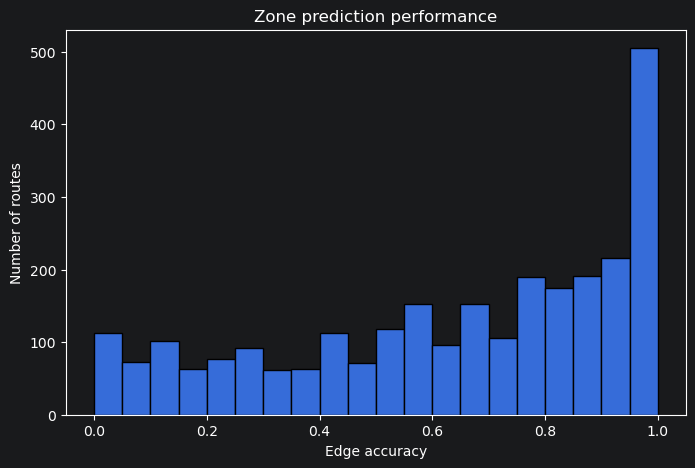

In [51]:
#plot distribuzione
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    results_df["edge_accuracy"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Edge accuracy")
plt.ylabel("Number of routes")
plt.title("Zone prediction performance")

plt.show()

In [55]:
T.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
A-1.1A,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1B,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1C,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1D,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1E,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [10]:
#inter tempi
#distanze euclidee
results = []

for route_id in valid_routes:

    # route ordinata secondo la sequenza reale
    route_actual = (
        df_actual[df_actual["route_id"] == route_id]
        .sort_values("actual_sequence")
    )

    route_zone = (
        route_actual.merge(
            df_stops[
                ["route_id", "stop_id", "zone_id"]
            ],
            on=["route_id", "stop_id"],
            how="left"
        )
    )

    true_zone_sequence = (
        route_zone["zone_id"]
        .dropna()
        .tolist()
    )

    # rimozione duplicati consecutivi
    true_zone_sequence_reduced = []

    for z in true_zone_sequence:

        if (
            len(true_zone_sequence_reduced) == 0
            or z != true_zone_sequence_reduced[-1]
        ):
            true_zone_sequence_reduced.append(z)

    # meno di 2 zone → impossibile definire archi
    if len(true_zone_sequence_reduced) < 2:
        continue

    route_zones = list(
        dict.fromkeys(true_zone_sequence_reduced)
    )

    start_zone = route_zones[0]

    pred_sequence = build_cost_time(
        route_zones=route_zones,
        start_zone=start_zone,
        T=T,
        P=P
    )

    acc = edge_accuracy(
        true_zone_sequence_reduced,
        pred_sequence
    )

    results.append(
        {
            "route_id": route_id,
            "n_zones": len(route_zones),
            "edge_accuracy": acc
        }
    )

In [11]:
#salvo i risultati finali
results_df = pd.DataFrame(results)

print("routes evaluated:", len(results_df))

print(
    "mean edge accuracy:",
    results_df["edge_accuracy"].mean()
)

print(
    "median edge accuracy:",
    results_df["edge_accuracy"].median()
)

print(
    "std:",
    results_df["edge_accuracy"].std()
)

routes evaluated: 2725
mean edge accuracy: 0.6163653264195168
median edge accuracy: 0.6818181818181818
std: 0.31274670996608955


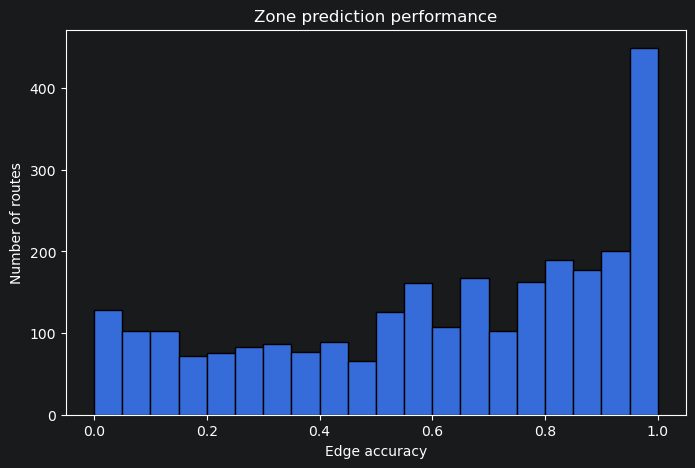

In [12]:
#plot distribuzione
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    results_df["edge_accuracy"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Edge accuracy")
plt.ylabel("Number of routes")
plt.title("Zone prediction performance")

plt.show()